# 07 · From a number to a probability

**Goal (Phase 7):** turn "Tatum: 27.3 points" into **P(over 26.5) = 58%**, because a bet needs a probability to compare with the odds.

Plan (roadmap):
1. **Residuals** = actual − predicted, on the training seasons. Look at their spread.
2. Start simple: points ~ Normal(mean = prediction, sd = residual sd).
3. Then let the sd **grow with the prediction** (Phase 2 funnel: high scorers swing more).
4. P(over line) = 1 − CDF(line). Lines are x.5, so there are no pushes.
5. **Calibration:** when we say 60%, does it happen ~60% of the time? (reliability plot)

No historical bookmaker lines exist yet, so for calibration we test against **stand-in lines** (e.g. the player's last-10 average rounded to x.5). Real lines from the logger come in Phase 8.

Model: the Phase 4 linear regression (kept over XGBoost and the two-stage model).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from fbml.config import ROOT

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

PROCESSED = ROOT / "nba" / "data" / "processed"
features = pd.read_parquet(PROCESSED / "features.parquet")

ID_COLS = ['season', 'player_id', 'player', 'team', 'opponent', 'game_id', 'date']
TARGET = 'points'
FEATURES = [c for c in features.columns if c not in ID_COLS + [TARGET, 'minutes']]

model_df = features.dropna(subset=FEATURES)
train = model_df[model_df['season'] <= 22024].copy()
test = model_df[model_df['season'] == 22025].copy()

# the Phase 4 model, refit here so this notebook stands on its own
lin_reg = make_pipeline(StandardScaler(), LinearRegression()).fit(train[FEATURES], train[TARGET])
train['pred'] = lin_reg.predict(train[FEATURES])
test['pred'] = lin_reg.predict(test[FEATURES])

print(train.shape, test.shape)
print(f"test MAE: {mean_absolute_error(test[TARGET], test['pred']):.3f}  (should be 4.499, same as Phase 4)")

(94510, 32) (25121, 32)
test MAE: 4.499  (should be 4.499, same as Phase 4)


5.9105453416106215
5.172504520187799e-16


<Axes: xlabel='resid', ylabel='Count'>

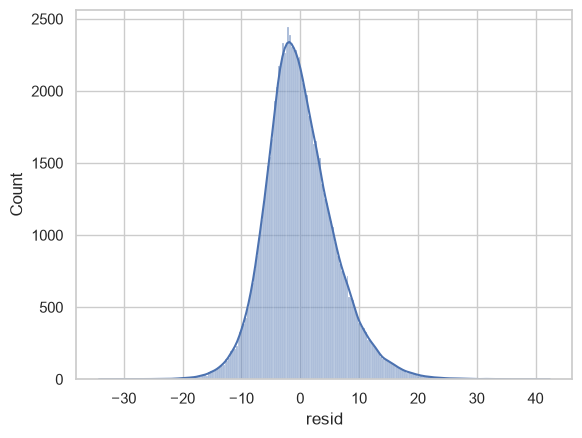

In [6]:
train['resid'] = train[TARGET] - train['pred']
print(train['resid'].std())
print(train['resid'].mean())
sns.histplot(train['resid'],kde=True)

In [8]:
# one Normal curve for everyone: points ~ Normal(mean = pred, sd = residual sd from TRAIN)
SD = train['resid'].std()

# stand-in line: last-10 average rounded down to x.5 (no historical bookmaker lines yet)
test['line'] = np.floor(test['points_last10']) + 0.5

test['p_over'] = 1 - stats.norm.cdf(test['line'], loc=test['pred'], scale=SD)
test['over'] = (test[TARGET] > test['line']).astype(int)   # what actually happened

print(f"SD: {SD:.2f}")
print(f"average predicted P(over): {test['p_over'].mean():.3f}")
print(f"actual over rate:          {test['over'].mean():.3f}")

SD: 5.91
average predicted P(over): 0.504
actual over rate:          0.459


In [ ]:
# reliability: within each band of predicted P(over), how often did it actually go over?
def reliability(df, p_col='p_over', y_col='over', n_bins=10):
    bins = pd.cut(df[p_col], bins=np.linspace(0, 1, n_bins + 1))
    return df.groupby(bins, observed=True).agg(predicted=(p_col, 'mean'), actual=(y_col, 'mean'), rows=(y_col, 'size'))

rel = reliability(test)
print(rel.round(3))

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], '--', color='grey', label='perfect calibration')
plt.scatter(rel['predicted'], rel['actual'], s=rel['rows'] / 50, label='Normal, one SD')
plt.xlabel('predicted P(over)')
plt.ylabel('actual over rate')
plt.title('Reliability on 2025-26 (stand-in lines)')
plt.legend();

In [ ]:
# Step 4: use the real error shape (empirical residuals) instead of a Normal curve
# P(over) = share of past residuals bigger than (line - pred). The skew is built in.
resid_sorted = np.sort(train['resid'].values)
gap = (test['line'] - test['pred']).values
test['p_over_emp'] = 1 - np.searchsorted(resid_sorted, gap) / len(resid_sorted)

print(f"average P(over): normal {test['p_over'].mean():.3f} | empirical {test['p_over_emp'].mean():.3f} | actual {test['over'].mean():.3f}")
reliability(test, p_col='p_over_emp').round(3)

In [ ]:
# Step 5: let the spread depend on the prediction (Phase 2 funnel: bigger scorers swing more)
# split train into 10 equal-size groups by predicted points; keep each group's own residuals
N_BUCKETS = 10
edges = np.quantile(train['pred'], np.linspace(0, 1, N_BUCKETS + 1))[1:-1]   # 9 inner cut points
train['bucket'] = np.digitize(train['pred'], edges)
test['bucket'] = np.digitize(test['pred'], edges)

resid_by_bucket = {b: np.sort(g['resid'].values) for b, g in train.groupby('bucket')}

spread = train.groupby('bucket').agg(pred_from=('pred', 'min'), pred_to=('pred', 'max'), resid_sd=('resid', 'std'))
print(spread.round(2))

def p_over_bucketed(df):
    out = np.empty(len(df))
    gaps = (df['line'] - df['pred']).values
    for b, resid in resid_by_bucket.items():
        mask = (df['bucket'] == b).values
        out[mask] = 1 - np.searchsorted(resid, gaps[mask]) / len(resid)
    return out

test['p_over_bucket'] = p_over_bucketed(test)

In [ ]:
# Step 6: compare the three methods
from sklearn.metrics import log_loss, brier_score_loss

def calib_error(df, p_col):
    # average gap between predicted and actual, weighted by rows in each bin (ECE)
    rel = reliability(df, p_col=p_col)
    return (rel['rows'] / rel['rows'].sum() * (rel['predicted'] - rel['actual']).abs()).sum()

methods = {'Normal, one SD': 'p_over', 'Empirical, all residuals': 'p_over_emp', 'Empirical, by prediction': 'p_over_bucket'}
scores = pd.DataFrame({
    name: {
        'mean P(over)': test[col].mean(),
        'log loss': log_loss(test['over'], test[col].clip(1e-4, 1 - 1e-4)),
        'brier': brier_score_loss(test['over'], test[col]),
        'calibration error': calib_error(test, col),
    } for name, col in methods.items()
}).T
print(f"actual over rate: {test['over'].mean():.3f}  |  coin-flip log loss: {np.log(2):.4f}")
print(scores.round(4))

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], '--', color='grey', label='perfect')
for name, col in methods.items():
    rel = reliability(test, p_col=col)
    rel = rel[rel['rows'] >= 200]   # skip tiny, noisy bins
    plt.plot(rel['predicted'], rel['actual'], 'o-', label=name)
plt.xlabel('predicted P(over)'); plt.ylabel('actual over rate'); plt.title('Reliability, 2025-26 (stand-in lines)')
plt.legend();

In [ ]:
# Save the chosen probability model (bucket edges + residuals) for Phase 8 and the live pipeline
MODELS = ROOT / "nba" / "models"
MODELS.mkdir(parents=True, exist_ok=True)
np.savez(MODELS / "prob_model_resid_buckets.npz",
         edges=edges, **{f"resid_{b}": r for b, r in resid_by_bucket.items()})
print("saved ->", MODELS / "prob_model_resid_buckets.npz")

## Phase 7 summary
- **Residuals:** sd 5.91, **right-skewed** (skew +0.53, median −0.58). On a typical night players score a bit *under* the prediction; the misses are big overs.
- **Normal curve, one SD:** says over too often. Average 50.4% vs 45.9% actual; calibration error 4.6 points. In betting that is as big as the bookmaker's margin, so it would "find" fake value on overs.
- **Empirical residuals** fix most of it (calibration error 1.9). **Grouped by prediction** is best: error 1.5, best log loss and Brier. The spread grows from sd 3.3 (low predictions) to 8.3 (stars), which is the Phase 2 funnel.
- **Chosen:** empirical residuals by prediction bucket, saved to `nba/models/prob_model_resid_buckets.npz`.
- **Caveat:** these are **stand-in lines** (last-10 average to x.5). Real bookmaker lines are sharper, so the real test is Phase 8 with the logger's lines. A small leftover over-bias (46.6% vs 45.9%) remains, so watch it there.
- **Note:** a constant "always 45.8%" guess is perfectly calibrated but has a much worse log loss (0.690). Calibration alone isn't enough; the model must also separate likely overs from likely unders.

In [11]:
test['p_over'] = pd.cut(test['p_over'], bins  = np.linspace(0,1,11))



TypeError: '<' not supported between instances of 'float' and 'pandas._libs.interval.Interval'